# Module 3: Fracture Position Detection — YOLO26


**Pipeline stages:**
1. Install dependencies
2. Download all 3 datasets via Roboflow
3. Imports & configuration
4. Create merged dataset structure
5. Copy & merge all datasets
6. Dataset summary
7. Write `data.yaml`
8. Train YOLO26
9. Evaluate on test set
10. Inference & visualize bounding boxes
11. Batch inference
12. Export model

In [1]:
import torch
print(torch.__version__)
print(torch.cuda.is_available())

2.11.0+cu130
True


## Download All 3 Datasets


In [2]:
import os
from pathlib import Path

BASE_DIR = r"/home/naefu/X-CV/"

BONE_FRACTURE_DIR = os.path.join(BASE_DIR, "BoneFractureByYolo", "bone fracture detection.v4-v4.yolov8")
XRAY_CV_DIR       = os.path.join(BASE_DIR, "XRayFractureCV")
FRACATLAS_DIR     = os.path.join(BASE_DIR, "FracAtlas")

# Verify
for name, path in [("Bone Fracture", BONE_FRACTURE_DIR),
                   ("X-Ray CV",      XRAY_CV_DIR),
                   ("FracAtlas",     FRACATLAS_DIR)]:
    img_count = len(list(Path(path).rglob("*.jpg"))) + len(list(Path(path).rglob("*.png")))
    print(f"  {name}: {img_count} images at {path}")

  Bone Fracture: 4148 images at /home/naefu/X-CV/BoneFractureByYolo/bone fracture detection.v4-v4.yolov8
  X-Ray CV: 2544 images at /home/naefu/X-CV/XRayFractureCV
  FracAtlas: 9980 images at /home/naefu/X-CV/FracAtlas


In [3]:
for name, path in [("Bone Fracture", BONE_FRACTURE_DIR),
                   ("X-Ray CV",      XRAY_CV_DIR),
                   ("FracAtlas",     FRACATLAS_DIR)]:
    img_count = len(list(Path(path).rglob("*.jpg"))) + len(list(Path(path).rglob("*.png")))
    print(f"  {name}: {img_count} images")

  Bone Fracture: 4148 images
  X-Ray CV: 2544 images
  FracAtlas: 9980 images


In [4]:
for folder_name, path in [("BoneFractureByYolo", BONE_FRACTURE_DIR),
                           ("XRayFractureCV",     XRAY_CV_DIR),
                           ("FracAtlas",          FRACATLAS_DIR)]:
    print(f"\n {folder_name}:")
    # Count per split
    for split in ["train", "valid", "val", "test"]:
        split_path = Path(path) / split / "images"
        if split_path.exists():
            count = len(list(split_path.glob("*.jpg"))) + len(list(split_path.glob("*.png")))
            print(f"   {split}: {count} images")
    # Show top level folders
    print(f"   Top-level contents:")
    for p in sorted(Path(path).iterdir()):
        print(f"      {p.name}")


 BoneFractureByYolo:
   train: 3631 images
   valid: 348 images
   test: 169 images
   Top-level contents:
      README.dataset.txt
      data.yaml
      test
      train
      valid

 XRayFractureCV:
   train: 2094 images
   valid: 299 images
   test: 151 images
   Top-level contents:
      README.dataset.txt
      README.roboflow.txt
      data (3).yaml
      data (4).yaml
      data.yaml
      test
      train
      valid

 FracAtlas:
   train: 9057 images
   valid: 820 images
   test: 103 images
   Top-level contents:
      README.dataset.txt
      README.roboflow.txt
      data (1).yaml
      data (2).yaml
      data.yaml
      test
      train
      valid


In [5]:
from pathlib import Path

BASE_DIR = r"E:\John GUC\Semester 10\Deep Learning\Project_Datasets"

for folder_name in ["BoneFractureByYolo", "XRayFractureCV", "FracAtlas"]:
    path = Path(BASE_DIR) / folder_name
    print(f"\n {folder_name}:")
    for p in sorted(path.rglob("*"))[:15]:
        print(f"   {p.relative_to(path)}")


 BoneFractureByYolo:

 XRayFractureCV:

 FracAtlas:


## Cell 3 — Imports & Configuration

> **Only `MERGED_DIR` and `PROJECT_DIR` need editing here**

In [6]:
import shutil
import yaml
import random

import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from ultralytics import RTDETR

# Merged dataset lives at this path (created on this machine from the 3 Roboflow sources)
MERGED_DIR  = "/home/naefu/X-CV/E:\\John GUC\\Semester 10\\Deep Learning\\Merged_Fracture"
PROJECT_DIR = "/home/naefu/X-CV/runs"
RUN_NAME    = "fracture_rtdetr"

random.seed(42)
print("Configuration loaded.")
print(f"Merged dataset → {MERGED_DIR}")
print(f"Training output → {PROJECT_DIR}/{RUN_NAME}")

Configuration loaded.
Merged dataset → /home/naefu/X-CV/E:\John GUC\Semester 10\Deep Learning\Merged_Fracture
Training output → /home/naefu/X-CV/runs/fracture_rtdetr


In [7]:
import sys
print(sys.version)
!python -c "import torch; print(torch.__version__)"

3.13.7 (main, Aug 15 2025, 12:34:02) [GCC 15.2.1 20250813]
2.11.0+cu130


## Create Merged Dataset Directory Structure

In [8]:
def create_dirs():
    for split in ["train", "val", "test"]:
        for sub in ["images", "labels"]:
            Path(f"{MERGED_DIR}/{split}/{sub}").mkdir(parents=True, exist_ok=True)
    print("Directory structure created:")
    for split in ["train", "val", "test"]:
        print(f"   {MERGED_DIR}/{split}/images  &  /labels")

create_dirs()

Directory structure created:
   /home/naefu/X-CV/E:\John GUC\Semester 10\Deep Learning\Merged_Fracture/train/images  &  /labels
   /home/naefu/X-CV/E:\John GUC\Semester 10\Deep Learning\Merged_Fracture/val/images  &  /labels
   /home/naefu/X-CV/E:\John GUC\Semester 10\Deep Learning\Merged_Fracture/test/images  &  /labels


## Copy & Merge All 3 Datasets

All 3 datasets are from Roboflow in YOLO format (`class_id cx cy w h`, normalized).
We prefix-rename files to avoid collisions and remap all class IDs to `0` (fracture).

In [9]:
def copy_yolo_dataset(src_dir: str, dataset_name: str):
    src = Path(src_dir)
    copied = 0

    for src_split, dst_split in [("train", "train"), ("valid", "val"), ("val", "val"), ("test", "test")]:
        img_src = src / src_split / "images"
        lbl_src = src / src_split / "labels"

        if not img_src.exists():
            if src_split == "train":
                img_src = src / "images"
                lbl_src = src / "labels"
            else:
                continue

        if not img_src.exists():
            print(f"  {dataset_name}/{src_split} — folder not found, skipping")
            continue

        images = list(img_src.glob("*.jpg")) + list(img_src.glob("*.png"))
        for img_path in images:
            lbl_path = lbl_src / (img_path.stem + ".txt")
            if not lbl_path.exists():
                continue

            new_stem = f"{dataset_name}_{img_path.stem}"
            dst_img  = Path(f"{MERGED_DIR}/{dst_split}/images/{new_stem}{img_path.suffix}")
            dst_lbl  = Path(f"{MERGED_DIR}/{dst_split}/labels/{new_stem}.txt")

            shutil.copy(img_path, dst_img)

            with open(lbl_path) as f:
                lines = f.readlines()
            with open(dst_lbl, "w") as f:
                for line in lines:
                    parts = line.strip().split()
                    if len(parts) == 5:
                        f.write(f"0 {' '.join(parts[1:])}\n")
            copied += 1

    print(f"{dataset_name}: {copied} images copied")
    return copied

# Clear and redo
for split in ["train", "val", "test"]:
    for sub in ["images", "labels"]:
        folder = Path(MERGED_DIR) / split / sub
        if folder.exists():
            shutil.rmtree(folder)
        folder.mkdir(parents=True, exist_ok=True)

print("=== Re-merging all 3 datasets ===")
n1 = copy_yolo_dataset(BONE_FRACTURE_DIR, "bone")
n2 = copy_yolo_dataset(XRAY_CV_DIR,       "xraycv")
n3 = copy_yolo_dataset(FRACATLAS_DIR,     "fracatlas")
print(f"\nGrand total: {n1 + n2 + n3} images in merged dataset")

=== Re-merging all 3 datasets ===
bone: 4148 images copied
xraycv: 2544 images copied
fracatlas: 9980 images copied

Grand total: 16672 images in merged dataset


## Dataset Summary

Merged Dataset Summary
───────────────────────────────────
  Train : 14782 images
  Val   :  1467 images
  Test  :   423 images
───────────────────────────────────
  Total : 16672 images


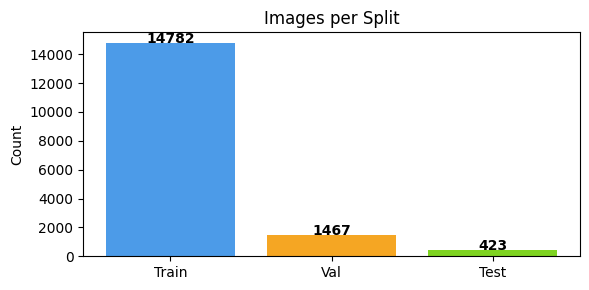

In [10]:
def count_split(split):
    img_dir = Path(MERGED_DIR) / split / "images"
    if not img_dir.exists():
        return 0
    return len(list(img_dir.glob("*.jpg"))) + len(list(img_dir.glob("*.png")))

train_n = count_split("train")
val_n   = count_split("val")
test_n  = count_split("test")
total   = train_n + val_n + test_n

print("Merged Dataset Summary")
print("─" * 35)
print(f"  Train : {train_n:>5} images")
print(f"  Val   : {val_n:>5} images")
print(f"  Test  : {test_n:>5} images")
print("─" * 35)
print(f"  Total : {total:>5} images")

fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(["Train", "Val", "Test"], [train_n, val_n, test_n],
       color=["#4C9BE8", "#F5A623", "#7ED321"])
ax.set_title("Images per Split")
ax.set_ylabel("Count")
for i, v in enumerate([train_n, val_n, test_n]):
    ax.text(i, v + 10, str(v), ha="center", fontweight="bold")
plt.tight_layout()
plt.show()

## Write `data.yaml`

In [11]:
def write_yaml():
    config = {
        "path":  MERGED_DIR,
        "train": "train/images",
        "val":   "val/images",
        "test":  "test/images",
        "nc":    1,
        "names": ["fracture"]
    }
    yaml_path = os.path.join(MERGED_DIR, "data.yaml")
    with open(yaml_path, "w") as f:
        yaml.dump(config, f, default_flow_style=False, sort_keys=False)
    print(f"data.yaml written to:\n   {yaml_path}")
    print("\nContents:")
    print("─" * 30)
    with open(yaml_path) as f:
        print(f.read())
    return yaml_path

YAML_PATH = write_yaml()


data.yaml written to:
   /home/naefu/X-CV/E:\John GUC\Semester 10\Deep Learning\Merged_Fracture/data.yaml

Contents:
──────────────────────────────
path: /home/naefu/X-CV/E:\John GUC\Semester 10\Deep Learning\Merged_Fracture
train: train/images
val: val/images
test: test/images
nc: 1
names:
- fracture



In [12]:
model = RTDETR("/home/naefu/X-CV/rtdetr-l.pt")

## Train YOLO26

Key decisions:
- **`yolo26n.pt`** — pretrained nano weights (COCO).
- **HSV hue/saturation = 0** — X-rays are grayscale.
- **`patience=15`** — early stopping to avoid overfitting
- **`mosaic=0.5`** — helps the model see fractures in different spatial contexts.

In [13]:
results = model.train(
    data=YAML_PATH,
    epochs=10,
    imgsz=640, 
    batch=10,
    project=PROJECT_DIR,
    name=RUN_NAME,

    # ── Augmentation tuned for X-ray images ──────────────────
    hsv_h=0.0,             # disable hue shift (grayscale images)
    hsv_s=0.0,             # disable saturation shift
    hsv_v=0.3,             # slight brightness variation
    flipud=0.3,            # vertical flip (bones appear in any orientation)
    fliplr=0.5,            # horizontal flip
    degrees=10,            # small rotation (bones at angles)
    mosaic=0.5,            # mosaic augmentation (helps small datasets)

    # ── Training stability ────────────────────────────────────
    patience=15,           # early stopping
    cos_lr=True,           # cosine LR schedule
    warmup_epochs=3,
    cache=True,            # cache images in RAM for speed
)

BEST_WEIGHTS = os.path.join(str(results.save_dir), "weights", "best.pt")
print(f"\nTraining complete!")
print(f"Best weights saved to: {BEST_WEIGHTS}")

New https://pypi.org/project/ultralytics/8.4.43 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.41 🚀 Python-3.13.7 torch-2.11.0+cu130 CUDA:0 (NVIDIA GeForce RTX 3080 Laptop GPU, 15982MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=10, bgr=0.0, box=7.5, cache=True, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/home/naefu/X-CV/E:\John GUC\Semester 10\Deep Learning\Merged_Fracture/data.yaml, degrees=10, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.3, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.0, hsv_s=0.0, hsv_v=0.3, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train

/home/naefu/.venvs/cv/lib/python3.13/site-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       1/10      7.96G      1.069      3.729     0.4874          0        640: 100% ━━━━━━━━━━━━ 1479/1479 2.0it/s 12:13<0.6s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 74/74 3.8it/s 19.7s0.3s
                   all       1467        591    0.00613      0.168    0.00252   0.000537

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
       2/10       8.1G     0.7624      1.268     0.4209          3        640: 0% ──────────── 0/1479  0.5s

/home/naefu/.venvs/cv/lib/python3.13/site-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       2/10      8.13G      1.015     0.9565     0.4599          0        640: 100% ━━━━━━━━━━━━ 1479/1479 2.0it/s 12:15<0.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 74/74 4.0it/s 18.5s0.3s
                   all       1467        591    0.00065      0.484    0.00162   0.000346

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
       3/10      8.22G      1.169     0.9581     0.7344          3        640: 0% ──────────── 0/1479  0.6s

...

       8/10      8.25G      1.318     0.5468     0.6687          3        640: 100% ━━━━━━━━━━━━ 1479/1479 2.1it/s 11:58<0.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 74/74 3.9it/s 19.1s0.3s
                   all       1467        591    0.00106      0.168    0.00049   7.78e-05

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
       9/10      8.19G      1.529     0.2893     0.5631          2        640: 0% ──────────── 0/1479  0.5s

/home/naefu/.venvs/cv/lib/python3.13/site-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       9/10      8.19G        nan        nan        nan          0        640: 100% ━━━━━━━━━━━━ 1479/1479 2.0it/s 12:02<0.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 74/74 4.0it/s 18.3s0.2s
                   all       1467        591          0          0          0          0
WARNING ⚠️ Skipping checkpoint save at epoch 8: EMA contains NaN/Inf

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
      10/10      8.08G       1.32     0.4737     0.3836          6        640: 0% ──────────── 0/1479  0.5s

/home/naefu/.venvs/cv/lib/python3.13/site-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      10/10      8.13G      1.142     0.6708     0.5245          1        640: 100% ━━━━━━━━━━━━ 1479/1479 2.1it/s 11:59<0.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 74/74 4.2it/s 17.5s0.2s
                   all       1467        591          0          0          0          0
WARNING ⚠️ Skipping checkpoint save at epoch 9: EMA contains NaN/Inf

10 epochs completed in 2.275 hours.
Optimizer stripped from /home/naefu/X-CV/runs/fracture_rtdetr-3/weights/last.pt, 66.2MB
Optimizer stripped from /home/naefu/X-CV/runs/fracture_rtdetr-3/weights/best.pt, 66.2MB

Validating /home/naefu/X-CV/runs/fracture_rtdetr-3/weights/best.pt...
Ultralytics 8.4.41 🚀 Python-3.13.7 torch-2.11.0+cu130 CUDA:0 (NVIDIA GeForce RTX 3080 Laptop GPU, 15982MiB)
rt-detr-l summary: 310 layers, 31,985,795 parameters, 0 gradients, 103.4 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 74/7

##  Evaluate on Test Set

In [14]:
eval_model = RTDETR(BEST_WEIGHTS)

metrics = eval_model.val(
    data=YAML_PATH,
    split="test",
    imgsz=640,
    conf=0.25,
)

print("\nTest Set Evaluation Results")
print("─" * 40)
print(f"  mAP@50       : {metrics.box.map50:.4f}")
print(f"  mAP@50-95    : {metrics.box.map:.4f}")
print(f"  Precision    : {metrics.box.mp:.4f}")
print(f"  Recall       : {metrics.box.mr:.4f}")

Ultralytics 8.4.41 🚀 Python-3.13.7 torch-2.11.0+cu130 CUDA:0 (NVIDIA GeForce RTX 3080 Laptop GPU, 15982MiB)
rt-detr-l summary: 310 layers, 31,985,795 parameters, 0 gradients, 103.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 96.6±141.1 MB/s, size: 25.2 KB)
val: Scanning /home/naefu/X-CV/E:\John GUC\Semester 10\Deep Learning\Merged_Fracture/test/labels.cache... 423 images, 272 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 423/423 197.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 27/27 3.0it/s 8.9s0.3s
                   all        423        209          0          0          0          0
Speed: 0.8ms preprocess, 19.7ms inference, 0.0ms loss, 0.2ms postprocess per image
Results saved to /home/naefu/X-CV/runs/detect/val-5

Test Set Evaluation Results
────────────────────────────────────────
  mAP@50       : 0.0000
  mAP@50-95    : 0.0000
  Precision    : 0.0000
  Recall       : 0.0000


## Inference on a Single X-Ray Image

Change `TEST_IMAGE_PATH` to any X-ray image you want to test on.


image 1/1 /home/naefu/X-CV/test.jpg: 640x640 (no detections), 30.9ms
Speed: 1.4ms preprocess, 30.9ms inference, 0.7ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /home/naefu/X-CV/runs/inference
0 label saved to /home/naefu/X-CV/runs/inference/labels


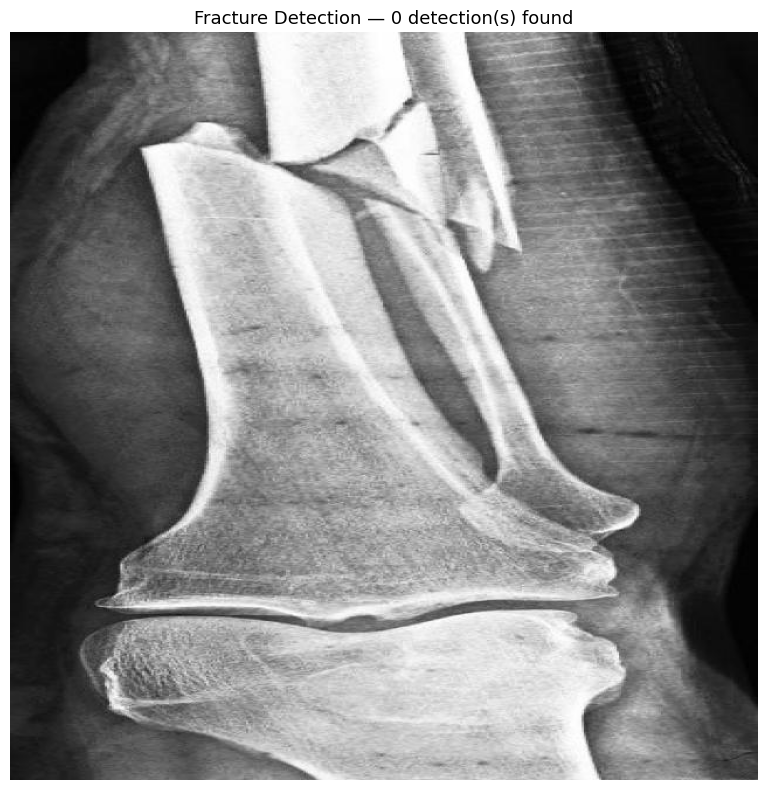


Structured output (for LLM module):


In [15]:
TEST_IMAGE_PATH = r"test.jpg"

infer_model = RTDETR(BEST_WEIGHTS)

results = infer_model.predict(
    source=TEST_IMAGE_PATH,
    conf=0.25,
    imgsz=640,
    save=True,
    save_txt=True,
    project=PROJECT_DIR,
    name="inference",
)

# ── Visualize inline ─────────────────────────────────────────
img_bgr = cv2.imread(TEST_IMAGE_PATH)
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

fig, ax = plt.subplots(1, 1, figsize=(10, 8))
ax.imshow(img_rgb, cmap="gray")

detections = []
for r in results:
    for box in r.boxes:
        x1, y1, x2, y2 = box.xyxy[0].tolist()
        conf = float(box.conf)

        rect = patches.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            linewidth=2, edgecolor="#00FF88", facecolor="none"
        )
        ax.add_patch(rect)
        ax.text(x1, y1 - 5, f"Fracture {conf:.2f}",
                color="#00FF88", fontsize=11, fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.2", facecolor="black", alpha=0.5))

        detections.append({
            "confidence" : conf,
            "bbox_xyxy"  : [x1, y1, x2, y2],
            "bbox_xywhn" : box.xywhn[0].tolist(),
        })

ax.set_title(f"Fracture Detection — {len(detections)} detection(s) found", fontsize=13)
ax.axis("off")
plt.tight_layout()
plt.show()

print("\nStructured output (for LLM module):")
for i, d in enumerate(detections):
    print(f"  Detection {i+1}: conf={d['confidence']:.3f}  bbox={[round(v,1) for v in d['bbox_xyxy']]}")

## Batch Inference on a Folder of X-Rays

In [16]:
INFERENCE_FOLDER = str(Path(MERGED_DIR) / "test" / "images")

infer_model = RTDETR(BEST_WEIGHTS)

batch_results = infer_model.predict(
    source=INFERENCE_FOLDER,
    conf=0.7,
    imgsz=640,
    save=True,
    project=PROJECT_DIR,
    name="batch_inference",
    stream=True,
)

all_detections = {}
for r in batch_results:
    fname = Path(r.path).name
    boxes = []
    for box in r.boxes:
        boxes.append({
            "confidence" : float(box.conf),
            "bbox_xyxy"  : box.xyxy[0].tolist(),
            "bbox_xywhn" : box.xywhn[0].tolist(),
        })
    all_detections[fname] = boxes
    status = f"{len(boxes)} fracture(s)" if boxes else "No fracture detected"
    print(f"  {fname:<40} {status}")

print(f"\nBatch inference complete. Results saved to {PROJECT_DIR}/batch_inference/")


image 1/423 /home/naefu/X-CV/E:\John GUC\Semester 10\Deep Learning\Merged_Fracture/test/images/bone_distal-humerus-fracture-1_jpg.rf.831cb137cfcbde1079f86abd5f5f2867.jpg: 640x640 (no detections), 32.1ms
  bone_distal-humerus-fracture-1_jpg.rf.831cb137cfcbde1079f86abd5f5f2867.jpg No fracture detected
image 2/423 /home/naefu/X-CV/E:\John GUC\Semester 10\Deep Learning\Merged_Fracture/test/images/bone_image1_0_png.rf.99862308d714bff3f9c410adf5ca93ac.jpg: 640x640 (no detections), 32.4ms
  bone_image1_0_png.rf.99862308d714bff3f9c410adf5ca93ac.jpg No fracture detected
image 3/423 /home/naefu/X-CV/E:\John GUC\Semester 10\Deep Learning\Merged_Fracture/test/images/bone_image1_1000_png.rf.a53c5e186c03961bf88075c6e3e94cf6.jpg: 640x640 (no detections), 32.0ms
  bone_image1_1000_png.rf.a53c5e186c03961bf88075c6e3e94cf6.jpg No fracture detected
image 4/423 /home/naefu/X-CV/E:\John GUC\Semester 10\Deep Learning\Merged_Fracture/test/images/bone_image1_1015_png.rf.3b7320c3c40771fa5532bf713a728b83.jpg: 6

## Export Model for Deployment

Export to ONNX or TensorRT for production use in the pipeline.

In [17]:
export_model = RTDETR(BEST_WEIGHTS)

# Choose your export format:
# 'onnx'        → universal, works anywhere
# 'torchscript' → PyTorch deployment
# 'tflite'      → mobile / edge devices
# 'engine'      → TensorRT (NVIDIA GPU, fastest inference)

exported_path = export_model.export(
    format="onnx",
    imgsz=640,
    dynamic=True,
    simplify=True,
)

print(f"\n Model exported to: {exported_path}")
print("Use this file in your production pipeline or LLM integration module.")

Ultralytics 8.4.41 🚀 Python-3.13.7 torch-2.11.0+cu130 CPU (11th Gen Intel Core i7-11800H @ 2.30GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino/
rt-detr-l summary: 310 layers, 31,985,795 parameters, 0 gradients, 103.4 GFLOPs

PyTorch: starting from '/home/naefu/X-CV/runs/fracture_rtdetr-3/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 300, 5) (63.1 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxslim>=0.1.71', 'onnxruntime-gpu'] not found, attempting AutoUpdate...
WARNING ⚠️ 
ERROR ❌ ONNX: export failure 697.9s: No module named 'onnx'


ModuleNotFoundError: No module named 'onnx'